# 02 · Revenue driver tree by market

*Demonstration project using public data (Olist). Not affiliated with any employer.*

**Revenue = customers × orders per customer × AOV**, monthly, for each market. Built by `python -m src.drivers`.

- *Customers* = unique customers in the month. For a multi-month period, monthly counts are summed
  ("customer-months"), so the identity holds for the period total.
- The change in revenue between two periods is split into one contribution per driver (LMDI method).
  The split is exact: contributions add up to each market's change, and markets add up to the total.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import config as cfg

P = cfg.PROCESSED_DIR
tree = pd.read_csv(P / "driver_tree_market.csv")
dec = pd.read_csv(P / "driver_decomposition.csv")
base = pd.read_csv(P / "driver_baseline.csv")
tree["month"] = pd.PeriodIndex(tree["month"], freq="M").to_timestamp()

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
    "font.family": ["Segoe UI", "DejaVu Sans"],
})
IMG = cfg.IMAGES_DIR
# same market colours as notebook 01 (slot order = revenue share): colour follows the market everywhere
MKT_COLOR = {"SP": SERIES[0], "Rest of Brazil": SERIES[1], "South": SERIES[2], "RJ": SERIES[3], "MG": SERIES[4]}
DRV_LABEL = {"customers": "Customers", "orders_per_customer": "Orders per customer", "aov": "AOV"}
DRV_COLOR = {"customers": SERIES[0], "orders_per_customer": SERIES[1], "aov": SERIES[2]}
brl_k = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:.1f}M" if abs(v) >= 1e6 else f"R$ {v/1e3:,.0f}k")

## 1. Where did revenue growth come from?

In [2]:
cols = ["market", "base_revenue", "current_revenue", "revenue_change", "revenue_growth",
        "customers_growth", "orders_per_customer_growth", "aov_growth",
        "contrib_customers", "contrib_orders_per_customer", "contrib_aov", "share_of_total_change"]
for label, g in dec.groupby("comparison", sort=False):
    print(f"{label}:  {g['base_period'].iloc[0]}  ->  {g['current_period'].iloc[0]}")
    t = g[cols].set_index("market")
    money = ["base_revenue", "current_revenue", "revenue_change", "contrib_customers",
             "contrib_orders_per_customer", "contrib_aov"]
    t[money] = (t[money] / 1e3).round(0)
    pcts = ["revenue_growth", "customers_growth", "orders_per_customer_growth", "aov_growth", "share_of_total_change"]
    t[pcts] = (t[pcts] * 100).round(1)
    display(t.rename(columns=lambda c: c + (" (R$k)" if c in money else " (%)")))

YoY Jan-Aug:  2017-01 to 2017-08  ->  2018-01 to 2018-08


,base_revenue (R$k),current_revenue (R$k),revenue_change (R$k),revenue_growth (%),customers_growth (%),orders_per_customer_growth (%),aov_growth (%),contrib_customers (R$k),contrib_orders_per_customer (R$k),contrib_aov (R$k),share_of_total_change (%)
market,,,,,,,,,,,
SP,1079.0,2919.0,1840.0,170.5,174.2,-0.8,-0.6,1865.0,-14.0,-10.0,43.6
RJ,428.0,875.0,447.0,104.5,114.7,-0.4,-4.4,478.0,-2.0,-28.0,10.6
MG,332.0,840.0,508.0,153.1,133.4,-0.4,8.8,464.0,-2.0,46.0,12.0
South,450.0,1034.0,584.0,129.7,116.2,-1.0,7.3,541.0,-7.0,50.0,13.8
Rest of Brazil,704.0,1550.0,846.0,120.1,121.1,-0.7,0.2,851.0,-7.0,2.0,20.0
Total,2993.0,7218.0,4225.0,141.1,141.6,-0.7,0.5,4198.0,-33.0,60.0,100.0


Last 6m vs prior 6m:  2017-09 to 2018-02  ->  2018-03 to 2018-08


,base_revenue (R$k),current_revenue (R$k),revenue_change (R$k),revenue_growth (%),customers_growth (%),orders_per_customer_growth (%),aov_growth (%),contrib_customers (R$k),contrib_orders_per_customer (R$k),contrib_aov (R$k),share_of_total_change (%)
market,,,,,,,,,,,
SP,1733.0,2243.0,509.0,29.4,26.8,-0.8,2.9,469.0,-16.0,57.0,68.2
RJ,676.0,647.0,-29.0,-4.3,-2.0,-0.5,-1.8,-13.0,-4.0,-12.0,-3.9
MG,596.0,620.0,24.0,4.0,4.8,-0.6,-0.3,29.0,-3.0,-2.0,3.2
South,662.0,783.0,122.0,18.4,6.9,-0.5,11.3,48.0,-3.0,77.0,16.3
Rest of Brazil,1053.0,1174.0,121.0,11.5,2.3,-0.9,10.0,25.0,-10.0,106.0,16.2
Total,4721.0,5467.0,747.0,15.8,12.5,-0.7,3.7,557.0,-36.0,226.0,100.0


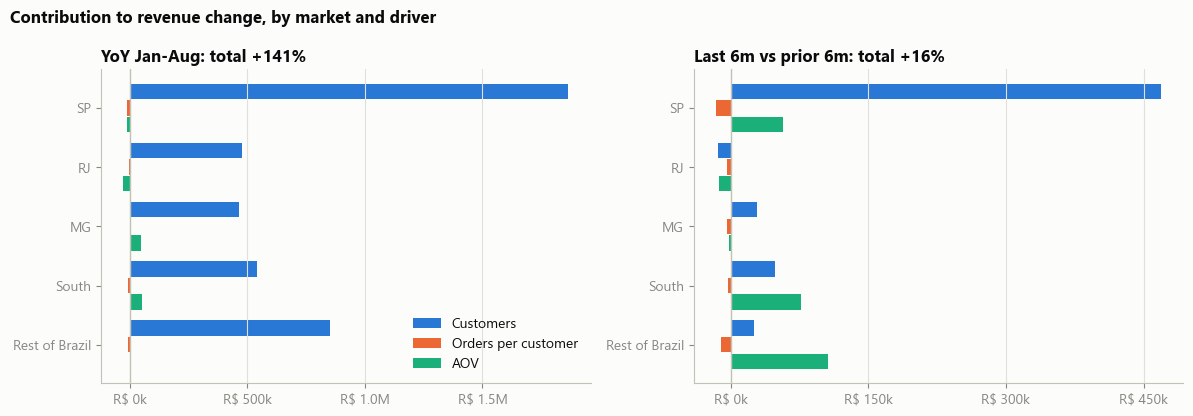

In [3]:
comps = list(dict.fromkeys(dec["comparison"]))
fig, axes = plt.subplots(1, len(comps), figsize=(12, 4.2))
markets = cfg.MARKETS[::-1]
h = 0.26
for ax, label in zip(axes, comps):
    g = dec[(dec["comparison"] == label)].set_index("market")
    for j, d in enumerate(cfg.DRIVERS):
        y = np.arange(len(markets)) + (1 - j) * (h + 0.02)
        ax.barh(y, g.loc[markets, f"contrib_{d}"], height=h, color=DRV_COLOR[d], label=DRV_LABEL[d])
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_yticks(np.arange(len(markets)), markets)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(5)); ax.xaxis.set_major_formatter(brl_k); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    tot = g.loc["Total"]
    ax.set_title(f"{label}: total {tot['revenue_growth']:+.0%}")
axes[0].legend(loc="lower right")
fig.suptitle("Contribution to revenue change, by market and driver", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "02_driver_contributions.png", dpi=150); plt.show()

In [4]:
for label, g in dec.groupby("comparison", sort=False):
    t = g[g["market"] == "Total"].iloc[0]
    parts = {d: t[f"contrib_{d}"] / t["revenue_change"] for d in cfg.DRIVERS}
    print(f"{label}: revenue {t['revenue_growth']:+.1%} (R$ {t['revenue_change']/1e6:+.2f}M). Share of the change: "
          + ", ".join(f"{DRV_LABEL[d]} {v:.0%}" for d, v in parts.items()))

YoY Jan-Aug: revenue +141.1% (R$ +4.22M). Share of the change: Customers 99%, Orders per customer -1%, AOV 1%
Last 6m vs prior 6m: revenue +15.8% (R$ +0.75M). Share of the change: Customers 75%, Orders per customer -5%, AOV 30%


## 2. How each driver moved

Raw driver values, one line per market. Orders per customer is cut at 1.05 so the month-to-month movement is visible;
Jan 2017 (first month, few customers) sits above that.

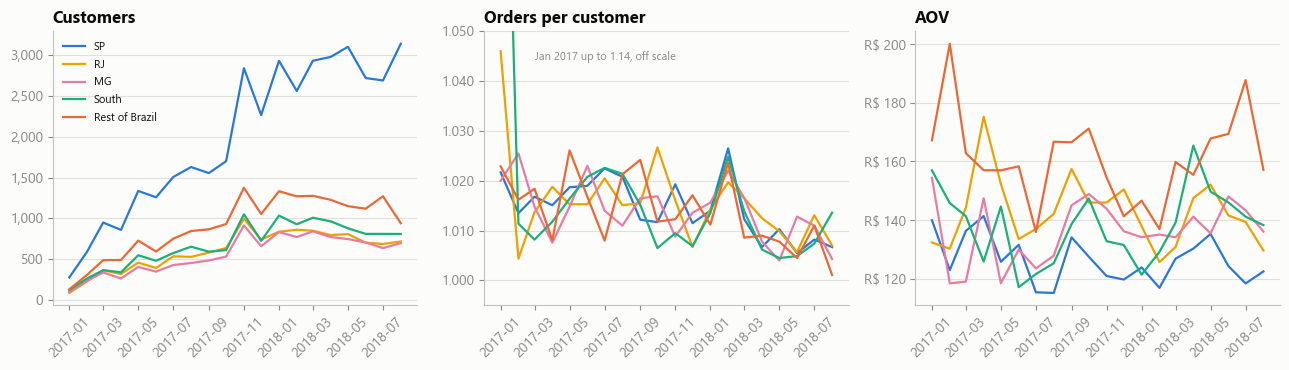

In [5]:
mk = tree[tree["market"] != "Total"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
fmts = {"customers": mtick.StrMethodFormatter("{x:,.0f}"), "orders_per_customer": mtick.StrMethodFormatter("{x:.3f}"),
        "aov": mtick.StrMethodFormatter("R$ {x:,.0f}")}
for ax, d in zip(axes, cfg.DRIVERS):
    for m in cfg.MARKETS:
        s = mk[mk["market"] == m]
        ax.plot(s["month"], s[d], color=MKT_COLOR[m], lw=1.6, label=m)
    ax.set_title(DRV_LABEL[d]); ax.yaxis.set_major_formatter(fmts[d]); ax.tick_params(axis="x", labelrotation=45)
axes[1].set_ylim(0.995, 1.05)
jan = mk[(mk["month"] == mk["month"].min())].set_index("market")["orders_per_customer"]
axes[1].text(pd.Timestamp("2017-03-01"), 1.046, f"Jan 2017 up to {jan.max():.2f}, off scale", color=MUTED, fontsize=8, va="top")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(IMG / "02_drivers_by_market.png", dpi=150); plt.show()

## 3. Baseline for scenarios

Average of the last 3 months of the window (Jun–Aug 2018). Stage 4 scenarios start from these values.
`customers_growth_vs_prior` compares monthly customers in Jun–Aug 2018 with Mar–May 2018.

In [6]:
b = base.set_index("market")
show = b[["customers", "orders_per_customer", "aov", "revenue", "revenue_share", "customers_growth_vs_prior"]].copy()
show["revenue"] = (show["revenue"] / 1e3).round(1)
show["revenue_share"] = (show["revenue_share"] * 100).round(1)
show["customers_growth_vs_prior"] = (show["customers_growth_vs_prior"] * 100).round(1)
show.rename(columns={"revenue": "revenue/month (R$k)", "revenue_share": "share (%)",
                     "customers_growth_vs_prior": "customers vs Mar-May (%)"}).round(3)

,customers,orders_per_customer,aov,revenue/month (R$k),share (%),customers vs Mar-May (%)
market,,,,,,
SP,2853.000,1.007,121.850,350.0,41.0,-5.1
RJ,702.667,1.008,136.843,97.0,11.4,-14.1
MG,679.667,1.009,142.563,97.8,11.5,-13.7
South,810.667,1.009,141.858,116.0,13.6,-14.8
Rest of Brazil,1111.667,1.006,172.975,193.4,22.7,-8.8
Total,6157.667,1.007,137.708,854.2,100.0,-9.2


## 4. What this means

In [7]:
y = dec[dec["comparison"] == comps[0]].set_index("market")
r = dec[dec["comparison"] == comps[1]].set_index("market")
tot = b.loc["Total"]
print(f"- Growth is customer-driven: over {comps[0]}, customers explain "
      f"{y.loc['Total','contrib_customers']/y.loc['Total','revenue_change']:.0%} of the R$ {y.loc['Total','revenue_change']/1e6:.2f}M increase.")
print(f"- Orders per customer barely moves (baseline {tot['orders_per_customer']:.3f}) and drags slightly in every market: "
      f"retention is not a lever in this data.")
print(f"- Over {comps[1]}, AOV explains {r.loc['Total','contrib_aov']/r.loc['Total','revenue_change']:.0%} of growth, "
      f"led by Rest of Brazil (AOV {r.loc['Rest of Brazil','aov_growth']:+.1%}) and South ({r.loc['South','aov_growth']:+.1%}).")
print(f"- SP delivered {r.loc['SP','share_of_total_change']:.0%} of the recent growth; RJ shrank "
      f"({r.loc['RJ','revenue_growth']:+.1%}).")
print(f"- Monthly customers in Jun-Aug 2018 were {tot['customers_growth_vs_prior']:+.1%} vs Mar-May: the recent trend is "
      f"down, so a baseline scenario should not assume 2017-style customer growth.")

- Growth is customer-driven: over YoY Jan-Aug, customers explain 99% of the R$ 4.22M increase.
- Orders per customer barely moves (baseline 1.007) and drags slightly in every market: retention is not a lever in this data.
- Over Last 6m vs prior 6m, AOV explains 30% of growth, led by Rest of Brazil (AOV +10.0%) and South (+11.3%).
- SP delivered 68% of the recent growth; RJ shrank (-4.3%).
- Monthly customers in Jun-Aug 2018 were -9.2% vs Mar-May: the recent trend is down, so a baseline scenario should not assume 2017-style customer growth.
